In [1]:
%pip install -q ultralytics opencv-python-headless pandas pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 49.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.1 MB/s eta 0:00:00


In [2]:
import sys
import cv2
import torch
import ultralytics

print("Python:", sys.version.split()[0])
print("OpenCV:", cv2.__version__)
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Check the Colab runtime settings.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Python: 3.13.15
OpenCV: 4.14.0
PyTorch: 2.11.0+cu130
Ultralytics: 8.4.182
CUDA available: True
GPU: Tesla T4


In [3]:
from pathlib import Path

PROJECT_DIR = Path("/content/visiontrack-ai")

directories = [
    "data/input",
    "outputs/videos",
    "outputs/detections",
    "outputs/analytics",
    "configs",
    "src",
]

for directory in directories:
    (PROJECT_DIR / directory).mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Directories created successfully.")

Project directory: /content/visiontrack-ai
Directories created successfully.


In [4]:
from google.colab import files
from pathlib import Path
import shutil

uploaded = files.upload()

video_extensions = {".mp4", ".avi", ".mov", ".mkv"}

candidates = [
    name for name in uploaded
    if Path(name).suffix.lower() in video_extensions
]

if not candidates:
    raise ValueError(
        "No supported video uploaded. Please upload an MP4, AVI, MOV, or MKV."
    )

source_name = candidates[0]
VIDEO_PATH = PROJECT_DIR / "data" / "input" / "traffic.mp4"

shutil.copy2(source_name, VIDEO_PATH)

print("Video saved to:", VIDEO_PATH)
print("File size:", round(VIDEO_PATH.stat().st_size / (1024**2), 2), "MB")

Saving Cars Moving On Road Stock Footage - Free Download.mp4 to Cars Moving On Road Stock Footage - Free Download.mp4
Video saved to: /content/visiontrack-ai/data/input/traffic.mp4
File size: 1.81 MB


In [5]:
import cv2

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError("OpenCV could not open the uploaded video.")

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = frame_count / fps if fps > 0 else None

ok, first_frame = cap.read()
cap.release()

if not ok or first_frame is None:
    raise RuntimeError("The video opened, but its first frame could not be read.")

print("VIDEO VALIDATION")
print("----------------")
print(f"Resolution: {width} x {height}")
print(f"FPS: {fps:.2f}")
print(f"Frame count: {frame_count}")
print(f"Duration: {duration:.2f} seconds" if duration else "Duration: unknown")
print("First frame decoded successfully.")

VIDEO VALIDATION
----------------
Resolution: 854 x 480
FPS: 29.97
Frame count: 718
Duration: 23.96 seconds
First frame decoded successfully.


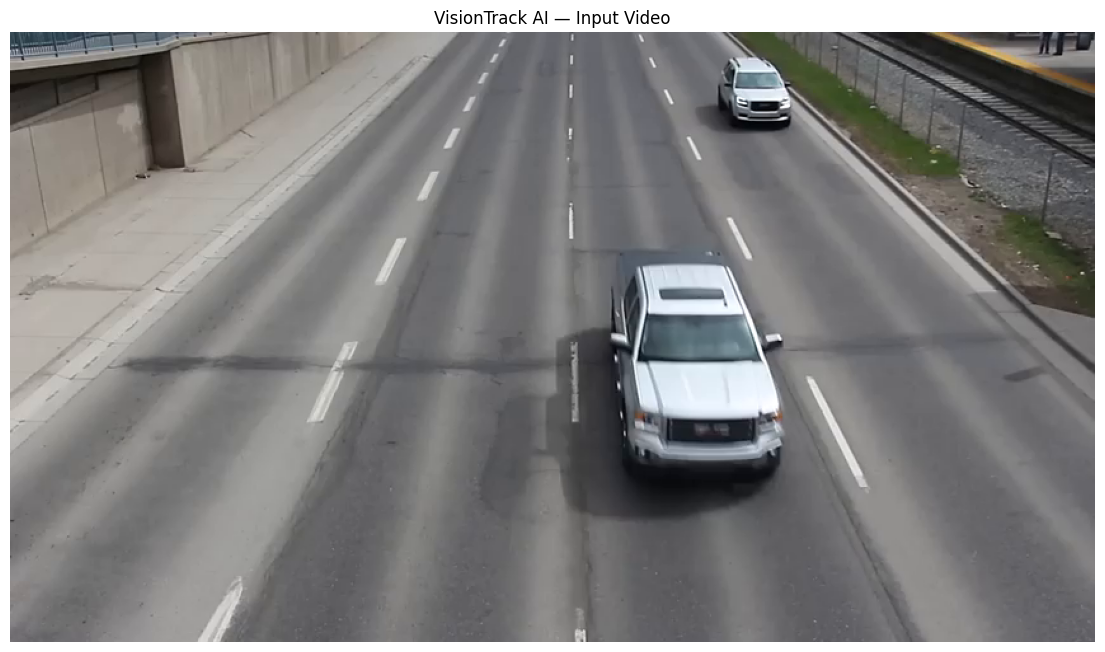

In [6]:
import matplotlib.pyplot as plt
import cv2

frame_rgb = cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(14, 8))
plt.imshow(frame_rgb)
plt.title("VisionTrack AI — Input Video")
plt.axis("off")
plt.show()

In [7]:
from pathlib import Path
from ultralytics import YOLO
import cv2
import torch
import time

# Project paths
PROJECT_DIR = Path("/content/visiontrack-ai")
VIDEO_PATH = PROJECT_DIR / "data/input/traffic.mp4"
OUTPUT_DIR = PROJECT_DIR / "outputs/videos"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PATH = OUTPUT_DIR / "detection_baseline.mp4"

# Check input
assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"

# Load pretrained detector
model = YOLO("yolo26n.pt")

# COCO vehicle classes: car, motorcycle, bus, truck
VEHICLE_CLASSES = [2, 3, 5, 7]

# Run inference
start_time = time.time()

results = model.predict(
    source=str(VIDEO_PATH),
    classes=VEHICLE_CLASSES,
    conf=0.25,
    imgsz=640,
    device=0 if torch.cuda.is_available() else "cpu",
    stream=True,
    verbose=False,
)

cap = cv2.VideoCapture(str(VIDEO_PATH))
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

writer = cv2.VideoWriter(
    str(OUTPUT_PATH),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height),
)

if not writer.isOpened():
    raise RuntimeError("Could not create the output video.")

frame_count = 0
detection_count = 0

try:
    for result in results:
        annotated_frame = result.plot()
        writer.write(annotated_frame)

        frame_count += 1
        detection_count += len(result.boxes)

        if frame_count % 100 == 0:
            print(
                f"Processed {frame_count} frames | "
                f"Detections so far: {detection_count}"
            )
finally:
    writer.release()

elapsed = time.time() - start_time

print("\n--- DETECTION BASELINE ---")
print("Frames processed:", frame_count)
print("Frame-level detections:", detection_count)
print(f"Processing time: {elapsed:.2f} seconds")
print(f"Processing speed: {frame_count / elapsed:.2f} FPS")
print("Output:", OUTPUT_PATH)

Processed 100 frames | Detections so far: 67
Processed 200 frames | Detections so far: 749
Processed 300 frames | Detections so far: 1639
Processed 400 frames | Detections so far: 2525
Processed 500 frames | Detections so far: 3770
Processed 600 frames | Detections so far: 4996
Processed 700 frames | Detections so far: 6288

--- DETECTION BASELINE ---
Frames processed: 716
Frame-level detections: 6474
Processing time: 23.10 seconds
Processing speed: 31.00 FPS
Output: /content/visiontrack-ai/outputs/videos/detection_baseline.mp4


In [11]:
!ffmpeg -y \
    -i /content/visiontrack-ai/outputs/videos/detection_baseline.mp4 \
    -c:v libx264 \
    -preset fast \
    -crf 23 \
    -pix_fmt yuv420p \
    -movflags +faststart \
    /content/visiontrack-ai/outputs/videos/detection_baseline_h264.mp4

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [12]:
from IPython.display import Video, display

display(Video(
    "/content/visiontrack-ai/outputs/videos/detection_baseline_h264.mp4",
    embed=True,
    width=900
))

In [13]:
from google.colab import files

files.download(str(OUTPUT_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>